<center><h1>Keehan_Alyssa_HW5</h1></center>
<br>
<br>

Name: Alyssa Keehan
<br>
Github Username: akeehan56
<br>
GitHub Links: [Class Repo](https://github.com/akeehan56/DSCI552) | [HW5](https://github.com/akeehan56/DSCI552/tree/main/HW5)
<br>
Email: akeehan@usc.edu
<br>
USC ID: 3429542433

## 1. Decision Trees as Interpretable Models

Import packages

In [7]:
# %pip install xgboost
#! brew install libomp

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inflamations Data Set

In [ ]:
columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pains",
    "urethral_burning_itch_swelling",
    "bladder_inflammation",
    "nephritis",
]

df = pd.read_csv(
    "../data/diagnosis.data",
    sep="\t",
    decimal=",",
    encoding="utf-16",
    header=None,
    names=columns,
)

df.head()

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,urethral_burning_itch_swelling,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### (b) Build a decision tree

#### 1. separate out features and target columns

In [13]:
feature_cols = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pains",
    "urethral_burning_itch_swelling",
]

target_cols = ["bladder_inflammation", "nephritis"]

#### 2. replace features with numeric values and combine target values to one variable

In [14]:
X = df[feature_cols].copy()
X = X.replace({"yes": 1, "no": 0})
y = df[target_cols].astype(str).agg(" + ".join, axis=1)
y

0       no + no
1      yes + no
2       no + no
3      yes + no
4       no + no
         ...   
115    no + yes
116     no + no
117    no + yes
118    no + yes
119    no + yes
Length: 120, dtype: str

#### 3. Fit the decision tree model to the data

In [16]:
tree = DecisionTreeClassifier(random_state=17)
tree.fit(X, y)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",17
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

#### 4. Plot the Decision Tree

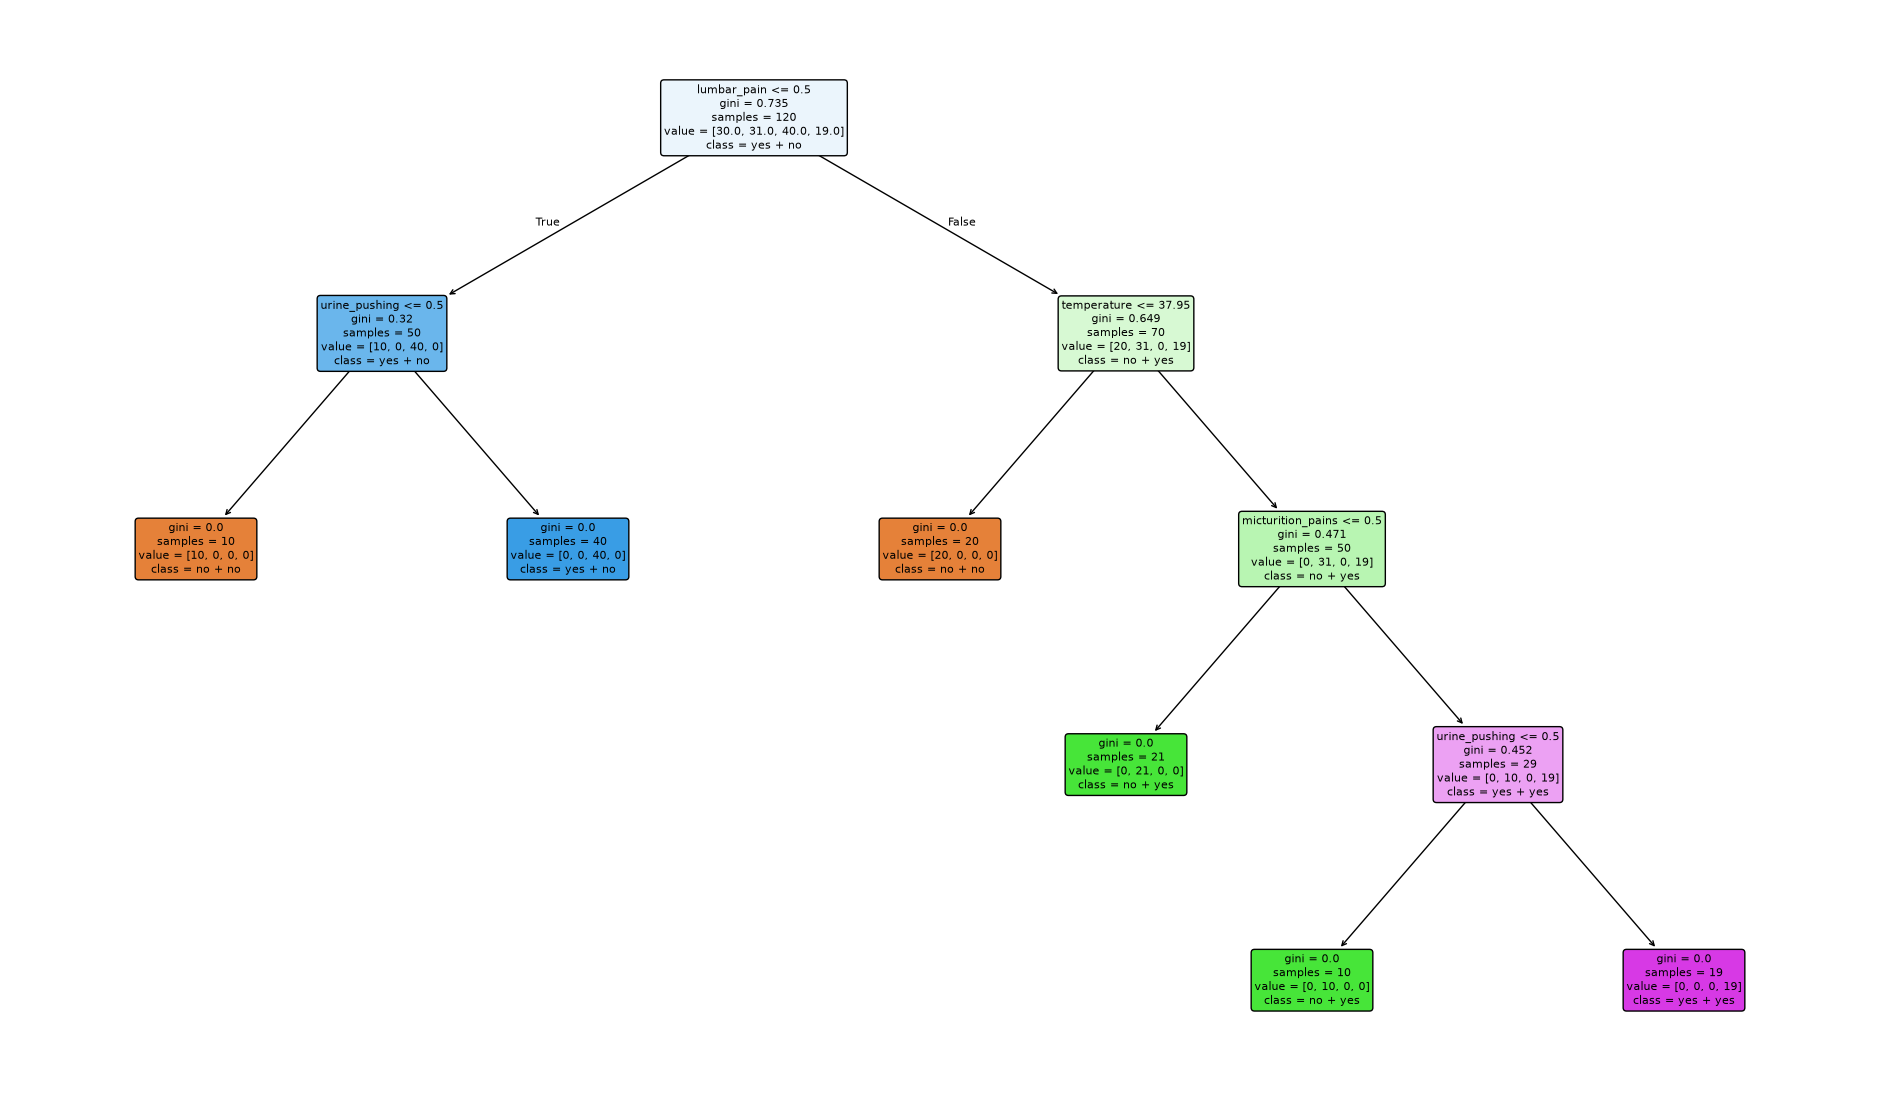

In [ ]:
plt.figure(figsize=(24, 14))
plot_tree(
    tree,
    feature_names=feature_cols,
    class_names=tree.classes_,
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.show()

### (c) Convert the decision rules

**Answer:**

- IF *lumbar_pain* <= 0.5 
    - AND *urine_pushing* <= 0.5
        - THEN predict **no + no**
    - AND *urine_pushing* > 0.5
        - THEN predict **yes + no**
- IF *lumbar_pain* > 0.5 
    - AND *temperature* <= 37.95
        - THEN predict **no + no**
    - AND *temperature* > 37.95 
        - AND *micturition_pains* <= 0.5
            - THEN predict **no + yes**
        - AND *micturition_pains* > 0.5 
            - AND *urine_pushing* <= 0.5
                - THEN predict **no + yes**
            - AND *urine_pushing* > 0.5
                - THEN predict **yes + yes**

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [19]:
raw = pd.read_csv("../data/communities.data", header=None, na_values="?")

#first 5 columns are non-repdeictve, so we will drop them. The last column is the target variable, so we will separate it from the predictors.
X = raw.iloc[:, 5:-1].copy()
y = raw.iloc[:, -1].copy()

# generalize names for the features and target variable
X.columns = [f"feature_{i}" for i in range(1, X.shape[1] + 1)]
y.name = "ViolentCrimesPerPop"

#first 1,495 rows for training and the rest for testing.
X_train = X.iloc[:1495].copy()
X_test = X.iloc[1495:].copy()
y_train = y.iloc[:1495].copy()
y_test = y.iloc[1495:].copy()

print(raw.shape)
print(X_train.shape)
print(X_test.shape)

(1994, 128)
(1495, 122)
(499, 122)


In [18]:
X

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,...,feature_113,feature_114,feature_115,feature_116,feature_117,feature_118,feature_119,feature_120,feature_121,feature_122
0,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.29,0.12,0.26,0.20,0.06,0.04,0.90,0.5,0.32,0.14
1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,NaN,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN
2,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,NaN,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN
3,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,...,NaN,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN
4,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,...,NaN,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1989,0.01,0.40,0.10,0.87,0.12,0.16,0.43,0.51,0.35,0.30,...,NaN,0.01,0.28,0.05,NaN,NaN,NaN,NaN,0.00,NaN
1990,0.05,0.96,0.46,0.28,0.83,0.32,0.69,0.86,0.73,0.14,...,NaN,0.02,0.37,0.20,NaN,NaN,NaN,NaN,0.00,NaN
1991,0.16,0.37,0.25,0.69,0.04,0.25,0.35,0.50,0.31,0.54,...,0.25,0.08,0.32,0.18,0.08,0.06,0.78,0.0,0.91,0.28
1992,0.08,0.51,0.06,0.87,0.22,0.10,0.58,0.74,0.63,0.41,...,0.19,0.03,0.38,0.33,0.02,0.02,0.79,0.0,0.22,0.18


In [20]:
y

0       0.20
1       0.67
2       0.43
3       0.12
4       0.03
        ... 
1989    0.09
1990    0.45
1991    0.23
1992    0.19
1993    0.48
Name: ViolentCrimesPerPop, Length: 1994, dtype: float64

### (b) Missing values

In [24]:
imputer = SimpleImputer(strategy="median", add_indicator=True)

# fit the imputer on the training set and transform it
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=imputer.get_feature_names_out(X_train.columns),
    index=X_train.index
)

# dont impute the test set, just transform it using the training set's imputer
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=imputer.get_feature_names_out(X_train.columns),
    index=X_test.index
)

**Answer:**

- After doing some reasearch and reading about the dataset, the recoemmendation is to use median imputation as to not get affected by the outliers in the predictor values.

### (c) Plot a correlation matrix

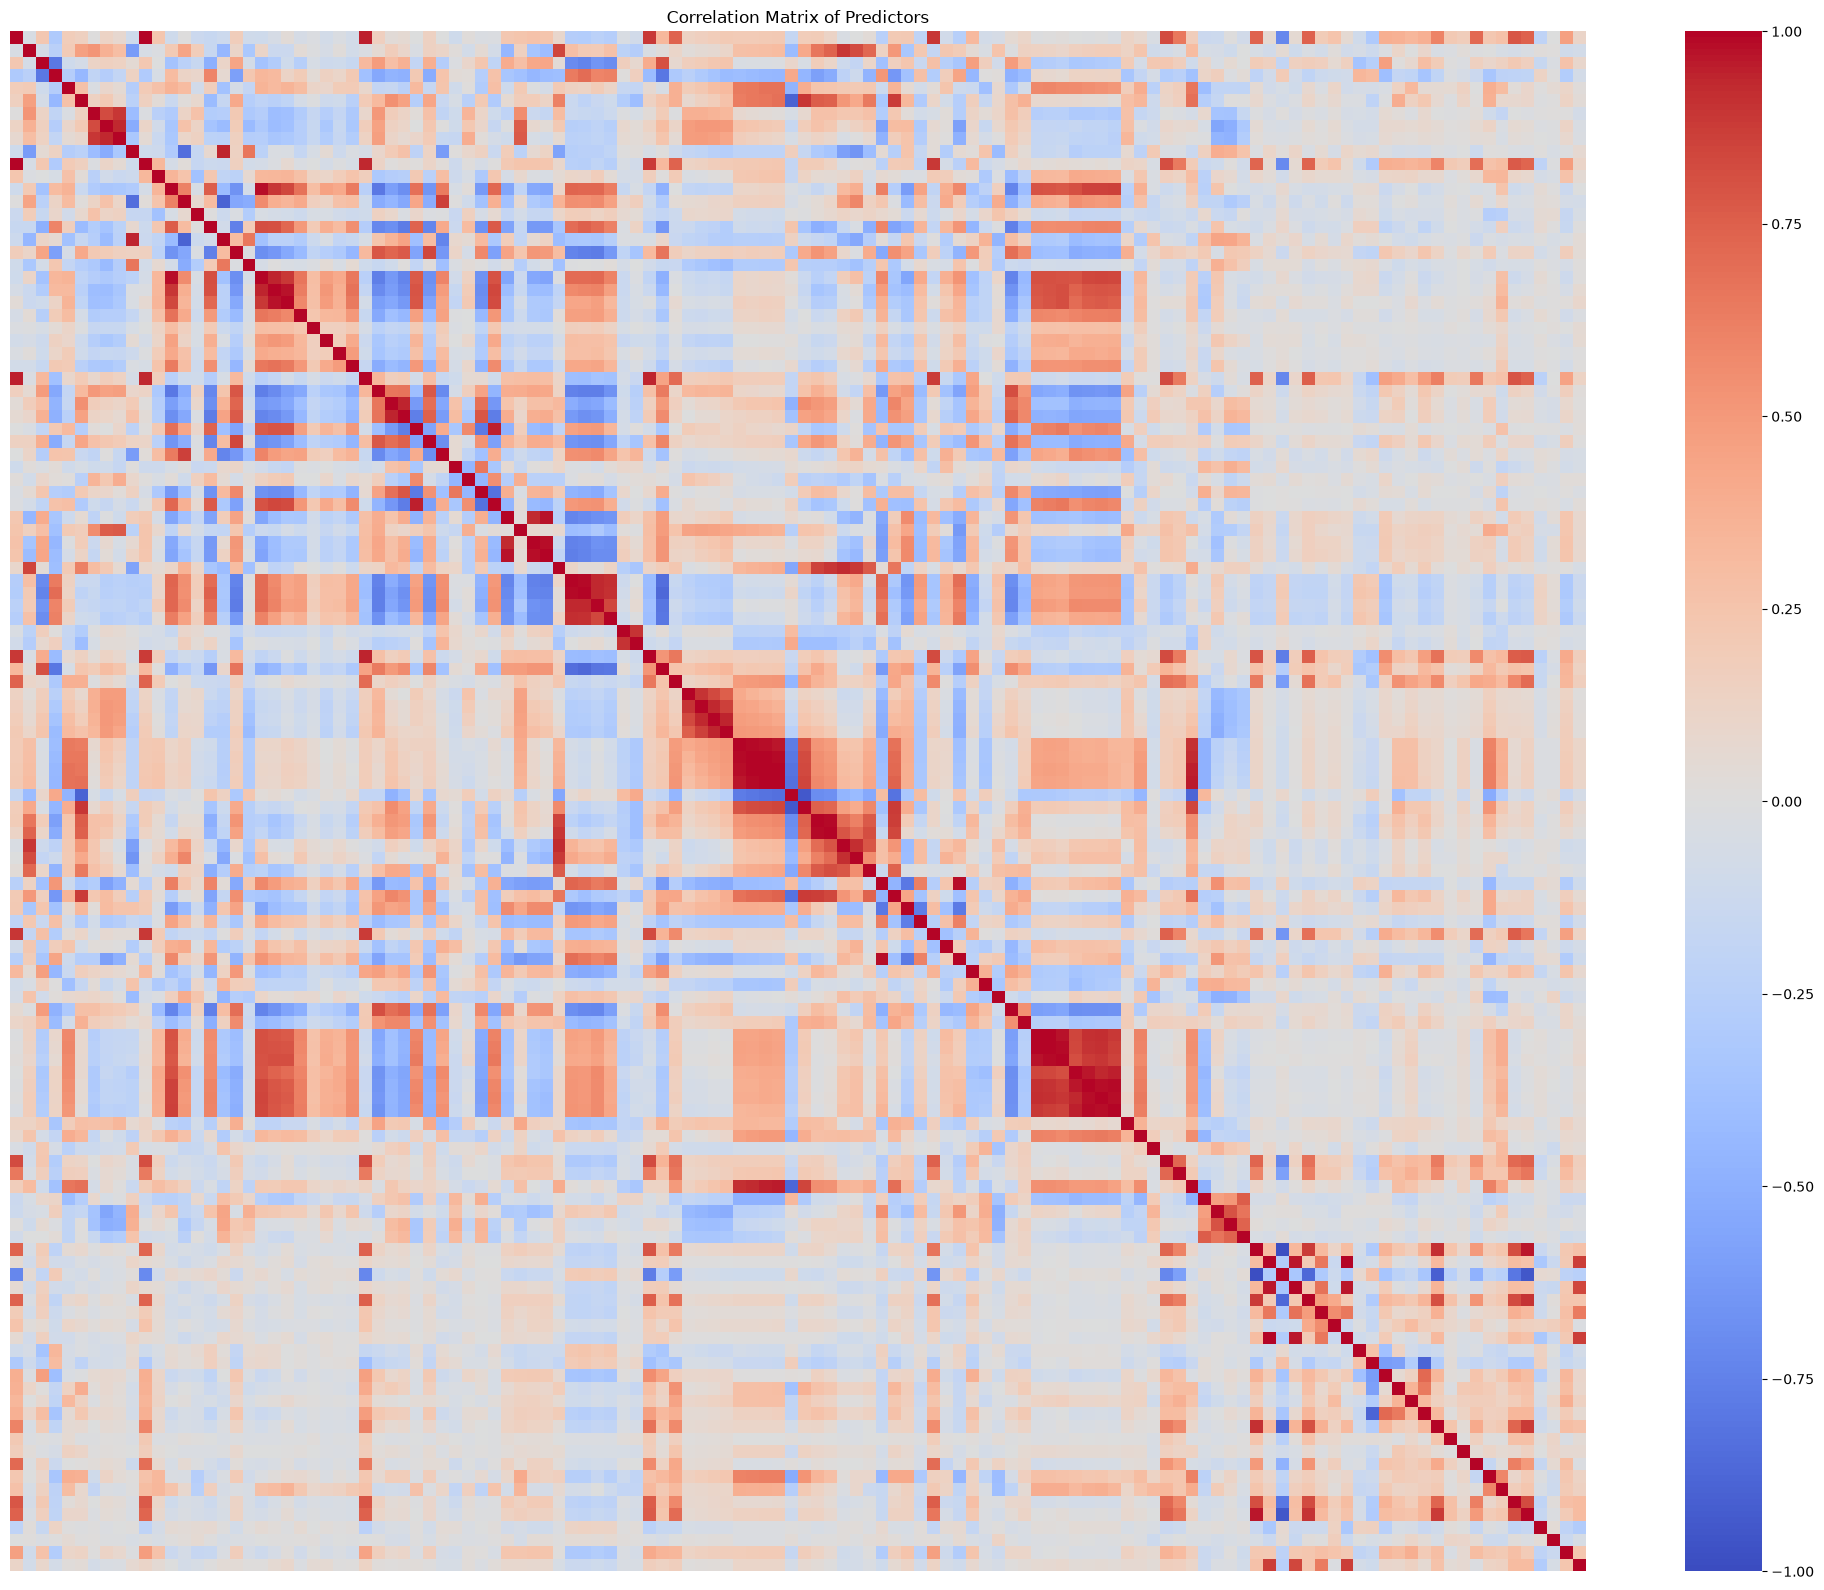

In [27]:
#combine rows, then keep just the original predictors for the correlation plot.
X_all_imputed = pd.concat([X_train_imputed, X_test_imputed]).sort_index()
correlation_matrix = X_all_imputed.loc[:, X_train.columns].corr()

plt.figure(figsize=(20, 16))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False
)
plt.title("Correlation Matrix of Predictors")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [28]:
features_imputed = X_all_imputed.loc[:, X_train.columns]

feature_means = features_imputed.mean()
feature_sds = features_imputed.std(ddof=1)

cv = (feature_sds / feature_means.replace(0, float("nan"))).sort_values(
    ascending=False
)
cv_percent = cv * 100

print(cv)

feature_109    5.447835
feature_91     4.407702
feature_90     3.485481
feature_50     2.994196
feature_52     2.900497
                 ...   
feature_112    0.143227
feature_105    0.126902
feature_119    0.117807
feature_106    0.117726
feature_99     0.057515
Length: 122, dtype: float64


### (e) Scatter plots and box plots for highest CV features

### (f) Fit a linear model

### (g) Fit a ridge regression model

### (h) Fit a LASSO model

### (i) Fit a PCR model

### (j) Fit a boosting tree